## Introduction

For day 10, the theme of the day is "air" and I tried to keep it simple making a map of "air temperature" using xarray.

In this code, a plot using the air temperature is done and this for Europe. The data are obtained from the [Climate Data Store](https://cds.climate.copernicus.eu/). In order to be able to download the data, please sign up for an account.

In what follows, we follow this [tutorial](https://ecmwf-projects.github.io/copernicus-training-c3s/reanalysis-climatology.html) here. However, we try to make the map a little fancier and play with the settings.

The code was run in Google Colab.




In [ ]:
!pip install cdsapi cartopy --quiet

## Importing the Python libraries

In [42]:
# code obtained from the tutorial:
# https://ecmwf-projects.github.io/copernicus-training-c3s/reanalysis-climatology.html
import cdsapi

# Libraries for working with multidimensional arrays
import numpy as np
import requests
import xarray as xr

# Libraries for plotting and visualising data
import matplotlib.path as mpath
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.feature as cfeature

# Disable warnings for data download via API
# import urllib3
# urllib3.disable_warnings()

/tmp/ipykernel_1018/3125842561.py:14: DeprecationWarning: The LONGITUDE_FORMATTER module-level attribute was deprecated in Cartopy 0.26. Use LongitudeFormatter instead.
  from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
/tmp/ipykernel_1018/3125842561.py:14: DeprecationWarning: The LATITUDE_FORMATTER module-level attribute was deprecated in Cartopy 0.26. Use LatitudeFormatter instead.
  from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER


In [43]:
import os
# Replace with your own CDS key and URL
KEY = "fill in your API key here"
URL = "https://cds.climate.copernicus.eu/api"

To see if the API key is installed successful:

In order to look for the data you need, you can visit the datasets where you can select your choice. It will automatically generate the following code.

For the data for "air temperature", the dataset [ERA5 monthly averaged data on single levels from 1940 to present](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-timeseries?tab=overview) is used. In this form, you select Monthly averaged reanalysis/2m temperature/2024/select all (months)/Sub-region extraction/NetCDF4/unarchived.

For "Sub-region extraction" you can fill in the following numbers (but you can change this or select "Whole available region" in case you want the data for the entire globe.

In [44]:
DATADIR = './'

In [45]:
c = cdsapi.Client(url=URL, key=KEY)

c.retrieve(
    "reanalysis-era5-single-levels-monthly-means",
    {
        "product_type": ["monthly_averaged_reanalysis"],
        "variable": ["2m_temperature"],
        "year": ["2026"],
        "month": ["01"],
        "time": ["00:00"],
        "data_format": "netcdf",
        "download_format": "unarchived",
        "area": [72, -25, 34, 40]
    },
    f"{DATADIR}Europe_monthly_jan_2026.nc"
)

2026-11-01 16:38:57,335 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
INFO:ecmwf.datastores.legacy_client:[2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
2026-11-01 16:38:57,867 INFO Request ID is 79aae974-2443-43ae-8a73-b3a5b3c33341
INFO:ecmwf.datastores.legacy_client:Request ID is 79aae974-2443-43ae-8a73-b3a5b3c33341
2026-11-01 16:38:58,032 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successf

90686d658ae284e4d650b4d378c9f1da.nc:   0%|          | 0.00/86.5k [00:00<?, ?B/s]

'./Europe_monthly_jan_2026.nc'

In [46]:
temp_eur = f'{DATADIR}Europe_monthly_jan_2026.nc'

In [47]:
ds = xr.open_dataset(temp_eur)

In [48]:
ds

<xarray.Dataset> Size: 163kB
Dimensions:     (valid_time: 1, latitude: 153, longitude: 261)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8B 2026-01-01
  * latitude    (latitude) float64 1kB 72.0 71.75 71.5 71.25 ... 34.5 34.25 34.0
  * longitude   (longitude) float64 2kB -25.0 -24.75 -24.5 ... 39.5 39.75 40.0
    number      int64 8B ...
    expver      <U4 16B ...
Data variables:
    t2m         (valid_time, latitude, longitude) float32 160kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-01T16:35 GRIB to CDM+CF via cfgrib-0.9.1...

Before procedding, we need to convert the longitude values as you can see in the output above, these are xx:

In [49]:
ds.longitude

<xarray.DataArray 'longitude' (longitude: 261)> Size: 2kB
array([-25.  , -24.75, -24.5 , ...,  39.5 ,  39.75,  40.  ])
Coordinates:
  * longitude  (longitude) float64 2kB -25.0 -24.75 -24.5 ... 39.5 39.75 40.0
    number     int64 8B ...
    expver     <U4 16B ...
Attributes:
    units:          degrees_east
    standard_name:  longitude
    long_name:      longitude

In [50]:
ds_180 = ds.assign_coords(longitude=(((ds.longitude + 180) % 360) - 180)).sortby('longitude')

In [51]:
# Create Xarray Data Array
da = ds_180['t2m']

In [52]:
da

<xarray.DataArray 't2m' (valid_time: 1, latitude: 153, longitude: 261)> Size: 160kB
[39933 values with dtype=float32]
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8B 2026-01-01
  * latitude    (latitude) float64 1kB 72.0 71.75 71.5 71.25 ... 34.5 34.25 34.0
  * longitude   (longitude) float64 2kB -25.0 -24.75 -24.5 ... 39.5 39.75 40.0
    number      int64 8B ...
    expver      <U4 16B ...
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      39933
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgua
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    K
    standard_name:                            unknown
    GRIB_surface:                             0.0

Convert everything in degrees:

In [53]:
da_degc = da - 273.15

In [54]:
da_degc

<xarray.DataArray 't2m' (valid_time: 1, latitude: 153, longitude: 261)> Size: 160kB
array([[[-16.082489 , -14.703583 , -14.0278015, ...,  -1.3266296,
          -1.3129578,  -1.3110046],
        [-16.225067 , -14.822723 , -13.424286 , ...,  -1.2309265,
          -1.2289734,  -1.2250671],
        [-13.096161 , -12.779755 , -12.369598 , ...,  -1.160614 ,
          -1.1488953,  -1.1410828],
        ...,
        [ 17.526886 ,  17.425323 ,  17.345245 , ...,   7.2846985,
           7.3647766,   7.386261 ],
        [ 17.59134  ,  17.507355 ,  17.442902 , ...,   7.3354797,
           7.4389954,   7.5483704],
        [ 17.64212  ,  17.61087  ,  17.565948 , ...,   7.323761 ,
           7.435089 ,   7.5639954]]], dtype=float32)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8B 2026-01-01
  * latitude    (latitude) float64 1kB 72.0 71.75 71.5 71.25 ... 34.5 34.25 34.0
  * longitude   (longitude) float64 2kB -25.0 -24.75 -24.5 ... 39.5 39.75 40.0
    number      int64 8B ...
    expver      <U4 16B ...
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      39933
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgua
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    K
    standard_name:                            unknown
    GRIB_surface:                             0.0

In [55]:
da_degc = da_degc.assign_attrs(da.attrs)
da_degc.attrs['units'] = '° C'

Create a simple plot without any formatting and this only for the first month of the year 2024:

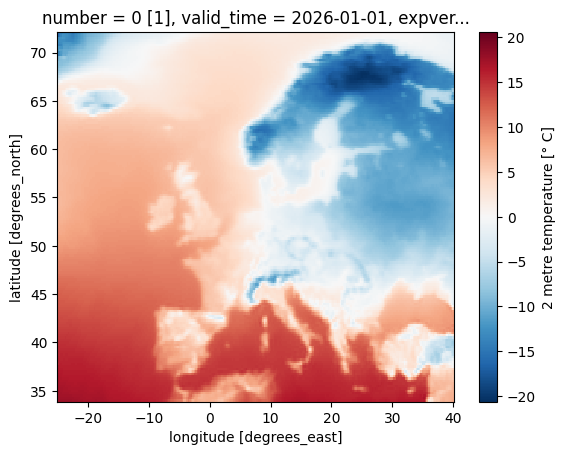

In [56]:
da_degc[0,:,:].plot()

Change the figure a bit:

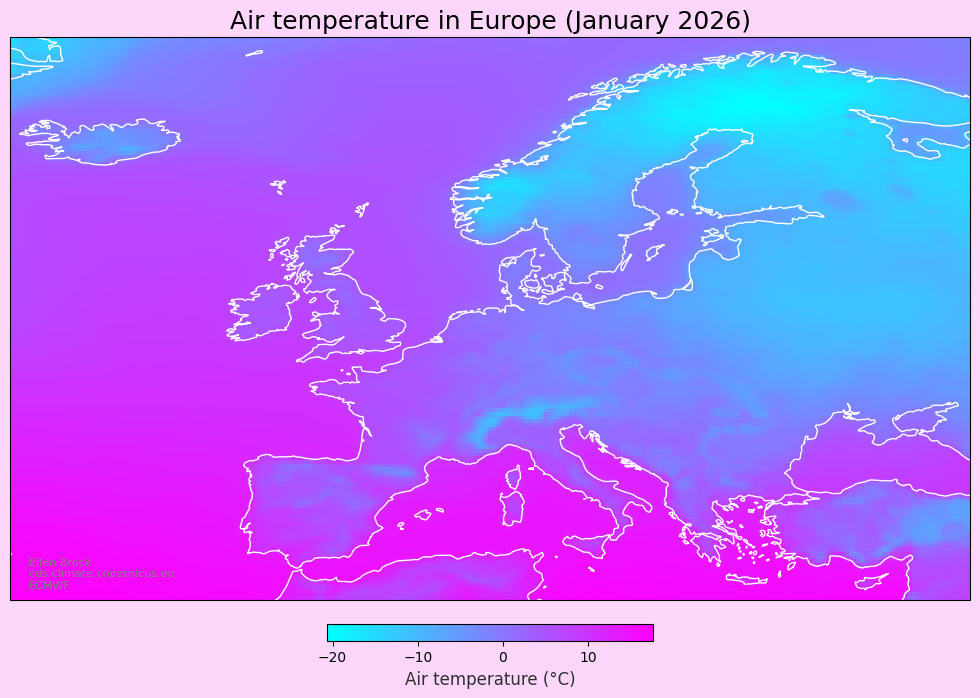

In [57]:
fig = plt.figure(figsize=(14, 8), facecolor = '#FCD7FB')
ax = plt.subplot(1,1,1, projection=ccrs.PlateCarree())
ax.coastlines(color='white') # Add coastlines
im = plt.pcolormesh(da_degc.longitude, da_degc.latitude, da_degc[0,:,:], cmap='cool')

plt.title("Air temperature in Europe (January 2026)", size = 18)

cbar = plt.colorbar(im,fraction=0.046, pad=0.04, location = 'bottom', shrink = 0.3)
cbar.set_label(
    f"Air temperature (°C)",
    size=12,
    color='#303030'
)
txt = ax.text(0.02, 0.02, "Ellen Brock \ncds.climate.copernicus.eu \nECMWF",
              size=8,
              color='gray',
              transform = ax.transAxes)

plt.savefig(
    "air_temperature_europe_jan_2026.png",
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor()
)

plt.show()

## Now it is your turn.

1. You can repeat the analysis with a different area.

2. Choose a different colour palette.

3. You can use any other of the Climate Data Store.

## References

https://ecmwf-projects.github.io/copernicus-training-c3s/reanalysis-climatology.html